# 01 · Análise pré-exploratória do WANDS

Objetivo: entender a estrutura e a qualidade dos três arquivos de `dataset/` antes de definir o protocolo de avaliação e o sistema de busca.

Este notebook **só lê** os dados; nada em `dataset/` é alterado. Os achados principais são registrados no `DEVLOG.md`, e os que afetam a avaliação, no `EVALUATION.md`.

Etapas:
1. Carga e visão geral (dimensões, tipos, nulos, chaves, duplicatas)
2. `product.csv`
3. `query.csv`
4. `label.csv` e raciocínio da divisão em treino, validação e teste
5. Pontos que afetam a avaliação (pooling e normalização de texto)

## Setup

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from wands_search import data, plots, profiling, split

plots.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

print("pandas", pd.__version__, "| numpy", np.__version__)
print("data dir:", data.DEFAULT_DATA_DIR)

pandas 3.1.1 | numpy 2.5.4
data dir: /Users/Work/development_personal/ml_challenge/dataset


## Etapa 1 · Carga e visão geral

A carga usa `wands_search.data`, que lê os TSV e renomeia `category hierarchy` para `category_hierarchy` **apenas na carga**, sem alterar o arquivo bruto.

Também comparamos o número de linhas lidas pelo pandas com o número de linhas do arquivo: uma diferença indicaria problema de parse (por exemplo, aspas ou quebras de linha dentro de `product_description`).

In [2]:
tables = data.load_all()
products, queries, labels = tables["product"], tables["query"], tables["label"]

for name, df in tables.items():
    n_lines = profiling.count_data_lines(data.DEFAULT_DATA_DIR / data.FILENAMES[name])
    print(f"{name:8s} rows_read={len(df):>7,}  file_lines={n_lines:>7,}  columns={df.shape[1]}")

product  rows_read= 42,994  file_lines= 42,994  columns=9
query    rows_read=    480  file_lines=    480  columns=3
label    rows_read=233,448  file_lines=233,448  columns=4


**Conclusões:** os três arquivos são lidos sem perda: o número de linhas lidas é igual ao do arquivo (42.994 produtos, 480 queries e 233.448 rótulos). O separador por tab funciona sem tratamento de aspas.

### Amostra de cada tabela

Cinco linhas aleatórias de cada tabela, com seed fixa, para vermos como os dados são. Textos longos aparecem cortados em 120 caracteres.

In [3]:
SAMPLE_SEED = 42

for name, df in tables.items():
    print(f"\n=== {name} ===")
    display(df.sample(5, random_state=SAMPLE_SEED))


=== product ===


,product_id,product_name,product_class,category_hierarchy,product_description,product_features,rating_count,average_rating,review_count
32193,32193,woven wire basket,"Boxes, Bins, Baskets, & Buckets",Storage & Organization / Storage Containers & Drawers / All Storage Containers,NaN,overalldepth-fronttoback:18|producttype : basket|features : stackable|overallheight-toptobottom:11.25|overalldepth-f...,21.0,5.0,19.0
21379,21379,scallop nightstand,Kids Nightstands,Baby & Kids / Toddler & Kids Bedroom Furniture / Kids Nightstands / Green Kids Nightstands,the scallop collection shows off its charming and lovely design with the scallop end table . this piece portrays an ...,framematerialdetails : mdf and plywood|theme : neutral|framematerial : manufactured wood|overallheight-toptobottom:2...,2.0,5.0,2.0
42275,42275,ybm home stainless steel colander,"Strainers, Colanders, & Salad Spinners","Kitchen & Tabletop / Kitchen Utensils & Tools / Colanders, Strainers, & Salad Spinners",this stainless steel colander with side handles will come in handy in your busy kitchen . the raised base keeps food...,overalldepth-fronttoback:11|overallproductweight:0.68|producttype : colander|overallproductweight:0.56|overallwidth-...,26.0,4.5,15.0
29885,29885,oneida 2 piece stainless steel strainer set,"Strainers, Colanders, & Salad Spinners","Kitchen & Tabletop / Kitchen Utensils & Tools / Colanders, Strainers, & Salad Spinners",NaN,producttype : strainer set|materialfinish : stainless steel|warrantylength : lifetime|material : stainless steel|rea...,1.0,5.0,1.0
8194,8194,ryland platform bed frame,Bed Frames|Beds,NaN,update the look of your room by adding the upholstered platform bed frame . this tailored platform frame creates a s...,color : black|overallwidth-sidetoside:60|overalllength-headtotoe:75|overallheight-toptobottom:15|legheight-toptobott...,2659.0,4.5,1676.0



=== query ===


,query_id,query,query_class
73,73,certified international melamine,Plates & Saucers
414,420,tile backsplash,Floor & Wall Tile
394,400,small ladies rocker swivel recliner,Recliners
277,281,brunk ship wheel,Decorative Objects
399,405,queen ann style living room chair,Accent Chairs



=== label ===


,id,query_id,product_id,label
67535,67686,26,14949,Partial
96482,96634,157,31490,Irrelevant
74096,74247,78,24497,Partial
226055,226622,123,38368,Irrelevant
60935,61086,5,1701,Exact


**Conclusões:** os ids não seguem a posição da linha (por exemplo, a linha 414 de `query.csv` tem `query_id` 420). Os cruzamentos entre tabelas devem usar sempre o id.

### Tipos e nulos por coluna

In [4]:
for name, df in tables.items():
    print(f"\n=== {name} ===")
    display(profiling.column_overview(df))


=== product ===


,dtype,nulls,null_pct,distinct
product_id,int64,0,0.00,42994
product_name,str,0,0.00,42577
product_class,str,2852,6.63,860
category_hierarchy,str,1556,3.62,1623
product_description,str,6008,13.97,33836
product_features,str,0,0.00,42979
rating_count,float64,9452,21.98,2861
average_rating,float64,9452,21.98,9
review_count,float64,9452,21.98,2310



=== query ===


,dtype,nulls,null_pct,distinct
query_id,int64,0,0.00,480
query,str,0,0.00,480
query_class,str,6,1.25,188



=== label ===


,dtype,nulls,null_pct,distinct
id,int64,0,0.0,233448
query_id,int64,0,0.0,480
product_id,int64,0,0.0,42986
label,str,0,0.0,3


**Conclusões**

**Nulos em `product.csv`:**
- `product_description`: 14% nulo. Próxima etapa: verificar se esses produtos têm as outras informações (`product_name`, `product_class` e `product_features`).
- `rating_count`, `average_rating` e `review_count`: 22% nulos. Próxima etapa: são nulos para os mesmos produtos? Podemos tratá-los como produtos novos?
- `product_class`: 6,6% nulo. Próxima etapa: podemos deduzir a partir de outras colunas?
- `category_hierarchy`: 3,6% nulo. Próxima etapa: podemos deduzir a partir de outras colunas?
- `product_features`: não tem nulos.

**Nulos em `query.csv`:**
- `query_class`: 6 queries nulas (1,25%). Próxima etapa: quais são essas queries?

**Cardinalidade:**
- São 860 `product_class` contra 188 `query_class`. Próxima etapa: são os mesmos valores?
- `average_rating` tem só 9 valores distintos. Próxima etapa: qual é a escala?

### Unicidade das chaves e linhas duplicadas

In [5]:
checks = {
    "product_id unique in product": products["product_id"].is_unique,
    "query_id unique in query": queries["query_id"].is_unique,
    "id unique in label": labels["id"].is_unique,
    "(query_id, product_id) unique in label": not labels.duplicated(["query_id", "product_id"]).any(),
}
for k, v in checks.items():
    print(f"{k:45s} {v}")

print()
print("duplicate rows in product (ignoring product_id):", products.drop(columns="product_id").duplicated().sum())
print("duplicate rows in query (ignoring query_id):    ", queries.drop(columns="query_id").duplicated().sum())
print("duplicate rows in label (ignoring id):          ", labels.drop(columns="id").duplicated().sum())

product_id unique in product                  True
query_id unique in query                      True
id unique in label                            True
(query_id, product_id) unique in label        False



duplicate rows in product (ignoring product_id): 0
duplicate rows in query (ignoring query_id):     0


duplicate rows in label (ignoring id):           1561


**Conclusões:** `product_id`, `query_id` e o `id` de `label.csv` são únicos. Não há produtos nem queries duplicados, mesmo ignorando o id. Já o par (query, produto) se repete em `label.csv`, o que investigamos a seguir.

### Pares (query, produto) repetidos em `label.csv`

O par `(query_id, product_id)` não é único. Verificamos se as repetições são cópias exatas (mesmo rótulo) ou **conflitos** (rótulos diferentes para o mesmo par), porque um conflito exigiria uma regra de resolução antes de treinar e avaliar.

In [6]:
pair_stats = profiling.label_pair_stats(labels)
repeated = pair_stats[pair_stats["n_rows"] > 1]
same_label = repeated[repeated["n_labels"] == 1]
conflicting = repeated[repeated["n_labels"] > 1]

total_rows = len(labels)
extra_rows = total_rows - len(pair_stats)
exact_copy_rows = labels.drop(columns="id").duplicated().sum()
conflict_rows = (conflicting["n_labels"] - 1).sum()
assert exact_copy_rows + conflict_rows == extra_rows

print("PAIRS (query_id, product_id)")
print(f"  distinct pairs:                     {len(pair_stats):>7,}")
print(f"  pairs appearing more than once:     {len(repeated):>7,}")
print(f"    same label in all rows:           {len(same_label):>7,}")
print(f"    different labels (conflicting):   {len(conflicting):>7,}")
print(f"  max rows for a single pair:         {pair_stats['n_rows'].max():>7,}")
print(f"  queries with repeated pairs:        {repeated.index.get_level_values('query_id').nunique():>7,}")
print()
print("ROWS")
print(f"  total rows:                         {total_rows:>7,}")
print(f"  extra rows (total - distinct pairs):{extra_rows:>7,}")
print(f"    exact copies, ignoring id:        {exact_copy_rows:>7,}  (safe to drop)")
print(f"    rows with a differing label:      {conflict_rows:>7,}  (need a resolution rule)")

conflicts = profiling.conflicting_label_rows(labels)
display(conflicts)

PAIRS (query_id, product_id)
  distinct pairs:                     231,873
  pairs appearing more than once:       1,467
    same label in all rows:             1,453
    different labels (conflicting):        14
  max rows for a single pair:               5
  queries with repeated pairs:            121

ROWS
  total rows:                         233,448
  extra rows (total - distinct pairs):  1,575
    exact copies, ignoring id:          1,561  (safe to drop)
    rows with a differing label:           14  (need a resolution rule)


,id,query_id,product_id,label
0,65,0,31306,Irrelevant
1,21650,0,31306,Partial
2,1325,12,34349,Exact
3,21761,12,34349,Partial
4,21764,12,34349,Partial
5,2380,24,696,Exact
6,21853,24,696,Partial
7,11489,89,24413,Exact
8,22346,89,24413,Partial
9,13869,106,1990,Partial


**Conclusões**

**Duplicatas em `label.csv`:**
- 1.561 linhas são cópias exatas (mesma query, mesmo produto e mesmo rótulo, mudando só o `id`). Podem ser removidas sem perda.
- 14 pares (query, produto) têm rótulos diferentes, de 231.873 pares distintos. Proposta: excluir esses pares, já que não temos uma regra de negócio para decidir qual rótulo vale. Restariam 231.859 pares.

**Cobertura dos rótulos:**
- Só 8 dos 42.994 produtos nunca foram julgados em nenhuma query.
- Cada query, porém, tem em média ~483 produtos julgados (231.873 pares / 480 queries), cerca de 1,1% do catálogo. A mediana é bem menor, como mostra a Etapa 4. Para os demais produtos, não sabemos se são relevantes para aquela query.
- Próxima etapa: como tratar, na avaliação do retrieval, um produto retornado que não foi julgado para a query?

## Etapa 2 · `product.csv`

Aqui respondemos as perguntas deixadas pela Etapa 1 sobre os produtos.

### 2.1 · Colunas numéricas de avaliação

Estas são as "features numéricas" que o desafio pede para usar no ranking. Queremos saber: os nulos são os mesmos produtos? Qual é a escala de `average_rating`? As contagens são muito concentradas em poucos produtos? As colunas são coerentes entre si (por exemplo, um produto ter mais reviews do que avaliações seria estranho)?

In [7]:
rating_columns = ["rating_count", "average_rating", "review_count"]
rating_nulls = products[rating_columns].isna()
print(f"all three columns null: {rating_nulls.all(axis=1).sum():>6,}")
print(f"any column null:        {rating_nulls.any(axis=1).sum():>6,}")

rated = products.dropna(subset=rating_columns)
display(rated[rating_columns].describe(percentiles=[0.5, 0.9, 0.99]).round(2))
print("average_rating values:")
display(rated["average_rating"].value_counts().sort_index().to_frame("products"))
print(f"rating_count == 0 among non-null:  {(rated['rating_count'] == 0).sum():>6,}")
print(f"review_count == 0 among non-null:  {(rated['review_count'] == 0).sum():>6,}")
print(f"review_count > rating_count:       {(rated['review_count'] > rated['rating_count']).sum():>6,}")

all three columns null:  9,452
any column null:         9,452


,rating_count,average_rating,review_count
count,33542.00,33542.00,33542.00
mean,430.27,4.53,284.25
std,2407.92,0.51,1539.61
min,1.00,1.00,0.00
50%,42.00,4.50,31.00
90%,748.00,5.00,495.00
99%,6123.85,5.00,3955.13
max,109226.00,5.00,61362.00


average_rating values:


,products
average_rating,
1.0,175
1.5,13
2.0,125
2.5,93
3.0,465
3.5,704
4.0,3568
4.5,17707
5.0,10692


rating_count == 0 among non-null:       0
review_count == 0 among non-null:     543
review_count > rating_count:            0


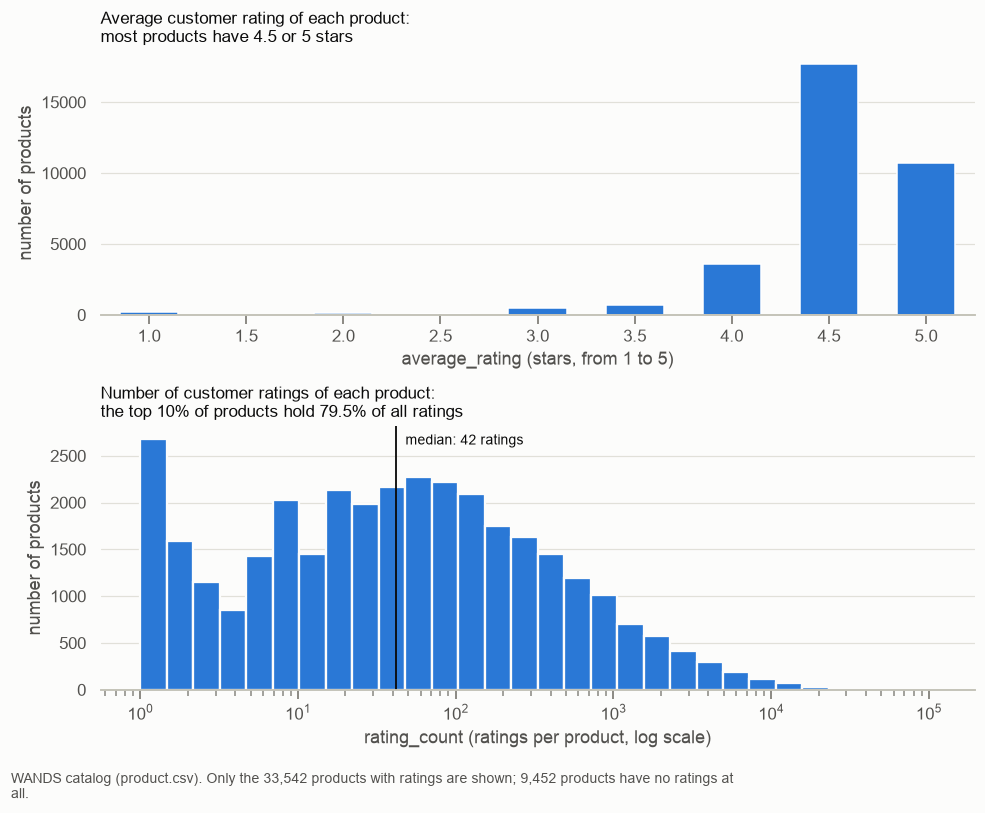

In [8]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 7))

rating_values = rated["average_rating"].value_counts().sort_index()
sns.barplot(x=rating_values.index.astype(str), y=rating_values.values, color=plots.SERIES_1, saturation=1, width=0.6, ax=top)
top.grid(axis="x", visible=False)
top.set_title("Average customer rating of each product:\nmost products have 4.5 or 5 stars")
top.set_xlabel("average_rating (stars, from 1 to 5)")
top.set_ylabel("number of products")

sns.histplot(rated["rating_count"], log_scale=True, bins=30, color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=bottom)
bottom.grid(axis="x", visible=False)
top_10pct_share = rated["rating_count"].nlargest(round(len(rated) * 0.1)).sum() / rated["rating_count"].sum() * 100
bottom.set_title(f"Number of customer ratings of each product:\nthe top 10% of products hold {top_10pct_share:.1f}% of all ratings")
bottom.set_xlabel("rating_count (ratings per product, log scale)")
bottom.set_ylabel("number of products")
plots.reference_line(bottom, rated["rating_count"].median(), f"median: {rated['rating_count'].median():.0f} ratings")

fig.tight_layout()
plots.add_caption(fig, f"WANDS catalog (product.csv). Only the {len(rated):,} products with ratings are shown; "
                       f"{len(products) - len(rated):,} products have no ratings at all.", width=115)
plt.show()

**Conclusões**

- `rating_count`, `average_rating` e `review_count` são nulas exatamente nos mesmos 9.452 produtos.
- Fora dos nulos, `rating_count` é sempre pelo menos 1, então nulo parece significar "sem avaliação".
- Não podemos afirmar que são produtos novos, porque o dataset não tem data. Proposta: criar uma feature "tem avaliação" em vez de imputar zero.
- `average_rating` vai de 1 a 5, em passos de 0,5. 85% dos produtos avaliados têm nota 4,5 ou 5, então a coluna distingue pouco os produtos.
- `rating_count` e `review_count` são muito concentradas: em `rating_count`, a mediana é 42, a média é 430 e o máximo é 109.226, e os 10% de produtos com mais avaliações têm 79,5% delas. Proposta: aplicar log antes de usar no ranking.
- As colunas são coerentes: `review_count` nunca passa de `rating_count`.

### 2.2 · `product_class` e `category_hierarchy`

Duas formas de categorizar o produto. `product_class` pode ter mais de um valor, separados por `|` (por exemplo, `Sofas|Sectionals`), e isso infla a contagem de 860 valores da Etapa 1. `category_hierarchy` vai do nível mais geral para o mais específico, separado por ` / `.

In [9]:
classes_per_product = products["product_class"].map(data.split_product_classes)
single_classes = classes_per_product.explode().dropna()
class_counts = single_classes.value_counts()

print("product_class values per product:")
display(classes_per_product.str.len().value_counts().sort_index().to_frame("products"))
print(f"distinct raw values:       {products['product_class'].nunique():>5,}")
print(f"distinct single values:    {class_counts.size:>5,}")
print(f"values with 1 product:     {(class_counts == 1).sum():>5,}")
print(f"values with < 10 products: {(class_counts < 10).sum():>5,}")
display(class_counts.head(10).to_frame("products"))

hierarchy_levels = products["category_hierarchy"].map(data.split_category_hierarchy)
print("levels per category_hierarchy:")
display(hierarchy_levels.str.len().value_counts().sort_index().to_frame("products"))
print(f"distinct top-level values: {hierarchy_levels.str[0].nunique()}")
print("top level, 15 most common:")
display(hierarchy_levels.str[0].value_counts(dropna=False).head(15).to_frame("products"))

product_class values per product:


,products
product_class,
0,2852
1,37895
2,2162
3,81
4,4


distinct raw values:         860
distinct single values:      601
values with 1 product:        98
values with < 10 products:   273


,products
product_class,
Accent Chairs,1426
Area Rugs,1320
Beds,1261
Coffee & Cocktail Tables,1138
Floor & Wall Tile,862
Dining Chairs,803
Bar Stools,794
Desks,752
End Tables,746


levels per category_hierarchy:


,products
category_hierarchy,
0,1556
1,103
2,1720
3,16297
4,16256
5,6453
6,609


distinct top-level values: 55
top level, 15 most common:


,products
category_hierarchy,
Furniture,16039
Home Improvement,4686
Décor & Pillows,4612
Outdoor,3394
Storage & Organization,2175
Lighting,2072
Rugs,2002
Bed & Bath,1865
Kitchen & Tabletop,1615


**Conclusões**

**`product_class`:**
- Os 860 valores da Etapa 1 são, na verdade, 601 valores individuais, porque 2.247 produtos têm mais de um valor em `product_class`. Próxima etapa: comparar `query_class` com os valores individuais de `product_class`.
- A distribuição é desigual: 273 valores de `product_class` têm menos de 10 produtos, e 98 têm um só.

**`category_hierarchy`:**
- A maioria dos valores de `category_hierarchy` tem de 3 a 5 níveis. O primeiro nível tem 55 valores distintos, mas é concentrado: o maior é Furniture, com 16.039 produtos (37% do catálogo), e a tabela mostra os 15 mais comuns.

### 2.3 · Dá para deduzir `product_class` e `category_hierarchy` uma da outra?

Pergunta da Etapa 1. Primeiro vemos quantos produtos têm uma informação e não a outra, porque só esses poderiam ser completados. Depois medimos o quanto uma coluna prevê a outra: em cada grupo, olhamos a fração de produtos que têm o valor mais comum. Quanto mais perto de 1, melhor a dedução funcionaria.

In [10]:
def modal_share(df: pd.DataFrame, by: str, target: str) -> float:
    """Share of rows whose target equals the most common target within their ``by`` group."""
    known = df.dropna(subset=[by, target])
    return known.groupby(by)[target].agg(lambda s: s.value_counts().iloc[0]).sum() / len(known)


has_product_class = products["product_class"].notna()
has_category_hierarchy = products["category_hierarchy"].notna()
print(f"product_class missing, category_hierarchy present: {(~has_product_class & has_category_hierarchy).sum():>6,}")
print(f"category_hierarchy missing, product_class present: {(has_product_class & ~has_category_hierarchy).sum():>6,}")
print(f"both missing:                                       {(~has_product_class & ~has_category_hierarchy).sum():>6,}")
print()
print(f"category_hierarchy -> product_class, modal share:  {modal_share(products, 'category_hierarchy', 'product_class'):.3f}")
print(f"product_class -> category_hierarchy, modal share:  {modal_share(products, 'product_class', 'category_hierarchy'):.3f}")

product_class missing, category_hierarchy present:  2,691
category_hierarchy missing, product_class present:  1,395
both missing:                                          161



category_hierarchy -> product_class, modal share:  0.947


product_class -> category_hierarchy, modal share:  0.765

**Conclusões**

- Só seria possível para parte dos nulos: 2.691 produtos têm `category_hierarchy` e não têm `product_class`, 1.395 têm `product_class` e não têm `category_hierarchy`, e 161 não têm nenhuma das duas.
- `category_hierarchy` prevê bem `product_class`: 94,7% dos produtos têm o `product_class` mais comum do seu `category_hierarchy`. O contrário funciona pior (76,5%).
- Esses números são otimistas: foram medidos nos mesmos dados, e valores de `category_hierarchy` com poucos produtos acertam quase por definição.
- Proposta: não imputar por enquanto, e deixar o campo vazio no texto indexado. Podemos rever isso na análise de erros.

### 2.4 · `product_name` e `product_description`

`product_name` e `product_description` são os principais textos para a busca. Olhamos o tamanho deles e os valores repetidos de `product_name`. Também respondemos a pergunta da Etapa 1: os produtos sem `product_description` têm as outras colunas?

In [11]:
name_tokens = products["product_name"].str.split().str.len()
description_tokens = products["product_description"].str.split().str.len()
display(pd.DataFrame({"name_tokens": name_tokens, "description_tokens": description_tokens})
        .describe(percentiles=[0.5, 0.9, 0.99]).round(1))

duplicated_names = products["product_name"].duplicated(keep=False)
print(f"products sharing product_name with another product: {duplicated_names.sum():,}")
display(products.loc[duplicated_names, "product_name"].value_counts().head(5).to_frame("products"))

no_description = products[products["product_description"].isna()]
print(f"products without product_description: {len(no_description):,}")
display((no_description[["product_name", "product_class", "category_hierarchy", "product_features"]]
         .notna().mean() * 100).round(1).to_frame("pct_present"))
print(f"pairs per product, with product_description:    {products.loc[products['product_description'].notna(), 'product_features'].map(data.parse_product_features).str.len().median():.0f} (median)")
print(f"pairs per product, without product_description: {no_description['product_features'].map(data.parse_product_features).str.len().median():.0f} (median)")

,name_tokens,description_tokens
count,42994.0,36986.0
mean,6.8,83.0
std,3.8,54.8
min,1.0,1.0
50%,6.0,76.0
90%,11.0,142.0
99%,20.0,295.0
max,49.0,791.0


products sharing product_name with another product: 768


,products
product_name,
indoor/outdoor seat/back cushion,6
coffee table,5
indoor/outdoor dining chair cushion,5
storage cabinet,5
wall shelf,5


products without product_description: 6,008


,pct_present
product_name,100.0
product_class,92.8
category_hierarchy,96.4
product_features,100.0


pairs per product, with product_description:    55 (median)
pairs per product, without product_description: 47 (median)


**Conclusões**

- Todos os 6.008 produtos sem `product_description` têm `product_name` e `product_features`, com 47 pares na mediana, contra 55 dos demais. Eles continuam pesquisáveis.
- `product_name` é curto (mediana de 6 palavras) e `product_description` é bem mais longo (mediana de 76).
- 768 produtos têm o mesmo `product_name` de outro, e os valores repetidos são genéricos, como "coffee table". `product_name` sozinho nem sempre distingue um produto.

### 2.5 · `product_features`

Campo com pares `chave : valor` separados por `|`. Queremos saber quantos pares cada produto tem, quais chaves são comuns (candidatas a sinal para a busca) e se chaves repetidas têm valores diferentes, o que sugeriria variantes do produto (por exemplo, mesma cama em vários tamanhos).

In [12]:
features = products["product_features"].map(data.parse_product_features)
exploded = (
    pd.DataFrame({"product_id": products["product_id"], "pair": features})
    .explode("pair")
    .dropna(subset="pair")
)
exploded["key"] = exploded["pair"].str[0]
exploded["value"] = exploded["pair"].str[1]

print("pairs per product:")
display(features.str.len().describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame("pairs").T)
print(f"distinct keys: {exploded['key'].nunique():,}")

per_product_key = exploded.groupby(["product_id", "key"])["value"].agg(["size", "nunique"])
print(f"products with a repeated key:               {per_product_key[per_product_key['size'] > 1].index.get_level_values('product_id').nunique():>7,}")
print(f"products with a key holding different values:{per_product_key[per_product_key['nunique'] > 1].index.get_level_values('product_id').nunique():>6,}")

key_coverage = (exploded.groupby("key")["product_id"].nunique() / len(products) * 100).round(1)
display(key_coverage.sort_values(ascending=False).head(20).to_frame("pct_of_products"))

pairs per product:


,count,mean,std,min,50%,90%,99%,max
pairs,42994.0,55.4,24.6,0.0,54.0,88.0,120.0,402.0


distinct keys: 7,961


products with a repeated key:                29,557
products with a key holding different values:29,547


,pct_of_products
key,
overallproductweight,92.6
countryoforigin,79.1
supplierintendedandapproveduse,75.6
overallheight-toptobottom,73.6
overallwidth-sidetoside,73.0
commercialwarranty,71.0
productwarranty,67.9
overalldepth-fronttoback,64.5
purposefuldistressingtype,61.2


**Conclusões**

- Tem 54 pares por produto na mediana e 7.961 chaves distintas. O mínimo é 0 pares por produto.
- Entre as chaves mais comuns estão peso, país de origem e garantia, que parecem pouco úteis para a busca. Próxima etapa: decidir quais chaves entram no texto indexado.
- 29.547 produtos (69%) têm uma chave com valores diferentes, como `overallwidth` com 64,7 e 43,3 no produto 0, que também lista `mattresssize` twin e queen. Isso sugere variantes do mesmo produto, mas é uma hipótese. Por causa disso, os valores numéricos dessas chaves são ambíguos como feature.

## Etapa 3 · `query.csv`

### 3.1 · Queries com `query_class` nulo e formato de `query`

Pergunta da Etapa 1: quais são as queries com `query_class` nulo? Também olhamos o tamanho e o formato de `query`, porque o processamento das buscas precisa tratar o texto do mesmo jeito que o texto dos produtos.

In [13]:
print("queries with null query_class:")
display(queries[queries["query_class"].isna()])

query_tokens = queries["query"].str.split().str.len()
print("tokens per query:")
display(query_tokens.value_counts().sort_index().to_frame("queries"))
print(f"queries with a non-lowercase character: {(queries['query'] != queries['query'].str.lower()).sum()}")
has_special = queries["query"].str.contains(r"[^a-zA-Z0-9 ]")
print(f"queries with a non-alphanumeric, non-space character: {has_special.sum()}")
display(queries.loc[has_special, ["query_id", "query"]].head(10))

queries with null query_class:


,query_id,query,query_class
194,197,desk for kids tjat ate 10 year old,NaN
204,207,dull bed with shirt head board,NaN
214,218,wand bunk beds,NaN
215,219,trinaic towel rod,NaN
218,222,small loving roomtables,NaN
220,224,twin over full bunk beds cool desins,NaN


tokens per query:


,queries
query,
1,23
2,109
3,169
4,99
5,41
6,16
7,11
8,8
9,3


queries with a non-lowercase character: 0
queries with a non-alphanumeric, non-space character: 15


,query_id,query
30,30,3 1/2 inch drawer pull
64,64,zachary 72.5
85,85,3/4 size mattress
180,181,e12/candelabra
186,188,"bedroom wall decor floral, multicolored with some teal (prints)"
200,203,ge top loading washer 4.5
205,208,"fawkes 36"" blue vanity"
219,223,wisdom stone river 3-3/4
234,238,outdoor seat/back cushion
272,276,chaves l-shape floating desk with hutch


**Conclusões**

- As 6 queries com `query_class` nulo parecem ter erros de digitação ou texto truncado, como "tjat", "desins", "roomtables" e "shirt head board". É uma leitura nossa das 6 queries, não algo que o dataset afirma.
- Isso mostra que há buscas com erros de digitação no dataset. Um buscador só por palavras não encontra "desins" em produtos com "designs". Próxima etapa: observar isso na análise de erros.
- `query` é curta: 63% das queries têm até 3 palavras, e 92% têm até 5.
- `query` já está toda em minúsculas.
- 15 queries têm caracteres especiais, como `3 1/2`, `72.5`, `e12/candelabra` e `36"`. Próxima etapa: comparar com o texto dos produtos, porque `product_name` escreve polegadas como `18 ''`, e `36"` pode não casar com ele.

### 3.2 · Os valores de `query_class` existem em `product_class`?

Pergunta da Etapa 1. Comparamos com os valores brutos de `product_class` e com os valores individuais, depois do split por `|`. Usamos `query_class` só para analisar os dados, nunca como entrada do sistema (ver `docs/EVALUATION.md`).

In [14]:
query_class_values = set(queries["query_class"].dropna())
raw_product_class_values = set(products["product_class"].dropna())
single_product_class_values = set(class_counts.index)

print(f"distinct query_class values:              {len(query_class_values):>4}")
print(f"query_class values containing '|':        {sum('|' in v for v in query_class_values):>4}")
print(f"found in raw product_class:               {len(query_class_values & raw_product_class_values):>4}")
print(f"found in single product_class values:     {len(query_class_values & single_product_class_values):>4}")

missing_values = sorted(query_class_values - single_product_class_values)
print(f"not found in single product_class values: {len(missing_values):>4}")
print(missing_values)

print()
print("products per query_class value (using single product_class values):")
products_per_query_class = class_counts.reindex(sorted(query_class_values)).fillna(0).astype(int)
display(products_per_query_class.describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_frame("products").T)
print(f"single product_class values with no query: {len(single_product_class_values - query_class_values):>4}")

distinct query_class values:               188
query_class values containing '|':           0
found in raw product_class:                182
found in single product_class values:      183
not found in single product_class values:    5
['Crock Pots & Slow Cookers', 'Door Mats', 'Flatware Serving Pieces', 'Free Weights', 'Uniters Outdoor Furniture']

products per query_class value (using single product_class values):


,count,mean,std,min,10%,50%,90%,max
products,188.0,195.8,242.0,0.0,24.4,109.0,511.3,1426.0


single product_class values with no query:  418


**Conclusões**

- Quase todos os valores são os mesmos: 183 dos 188 valores de `query_class` existem em `product_class` depois do split.
- Sem o split, seriam 182, então o split muda pouco nesta comparação.
- 5 valores de `query_class` não existem em `product_class`: `Crock Pots & Slow Cookers`, `Door Mats`, `Flatware Serving Pieces`, `Free Weights` e `Uniters Outdoor Furniture`. Podem ser nomes diferentes para o mesmo tipo de produto, o que não verificamos.
- As queries cobrem só parte do catálogo: 418 dos 601 valores individuais de `product_class` não aparecem em nenhuma `query_class`.

### 3.3 · Distribuição de `query_class`

Queremos saber se dá para **estratificar** a divisão por `query_class`, ou seja, manter a mesma proporção de cada valor em treino, validação e teste. Para isso, cada valor precisa de pelo menos 3 queries, uma para cada parte.

In [15]:
queries_per_class = queries["query_class"].value_counts()

display(queries_per_class.describe(percentiles=[0.5, 0.9]).round(1).to_frame("queries_per_query_class").T)
print(f"query_class values with 1 query:     {(queries_per_class == 1).sum():>4}")
print(f"query_class values with < 3 queries: {(queries_per_class < 3).sum():>4}")
display(queries_per_class.head(10).to_frame("queries"))

,count,mean,std,min,50%,90%,max
queries_per_query_class,188.0,2.5,2.9,1.0,1.0,6.0,20.0


query_class values with 1 query:       98
query_class values with < 3 queries:  139


,queries
query_class,
Wall Art,20
Accent Chairs,16
Beds,15
Area Rugs,15
Coffee & Cocktail Tables,10
Dressers & Chests,10
Desks,9
Accent Pillows,8
Wall Décor,8


**Conclusões**

- **Não dá para estratificar por `query_class`:** 139 dos 188 valores (74%) têm menos de 3 queries, e 98 têm só uma.
- Proposta: fazer a divisão por query, com seed fixa, equilibrando as queries pelo perfil de `label` (ver `docs/EVALUATION.md`).

### 3.4 · Queries quase iguais

Vamos dividir as queries em treino, validação e teste. Se "salon chair" ficar no treino e "salon chairs" no teste, o modelo já terá visto quase a mesma busca, e a nota no teste sai melhor do que deveria. Por isso procuramos queries que só mudam em maiúsculas, ordem das palavras ou plural. É uma regra simples, então não pega sinônimos nem erros de digitação.

In [16]:
group_keys = queries["query"].map(profiling.query_group_key)
group_sizes = group_keys.map(group_keys.value_counts())
near_duplicates = queries.assign(group_key=group_keys)[group_sizes > 1].sort_values("group_key")

print(f"distinct group keys: {group_keys.nunique()}")
print(f"queries in a group with more than one query: {len(near_duplicates)}")
display(near_duplicates)

distinct group keys: 479
queries in a group with more than one query: 2


,query_id,query,query_class,group_key
26,26,leather chairs,Accent Chairs,chair leather
151,151,leather chair,Accent Chairs,chair leather


**Conclusões**

- Só um grupo de queries quase iguais apareceu: "leather chair" e "leather chairs".
- Proposta: manter as duas na mesma parte da divisão. O impacto é mínimo, mas evita o problema a custo baixo.
- A regra não detecta sinônimos nem erros de digitação, então pode haver queries parecidas que ela não encontrou.

## Etapa 4 · `label.csv`

### 4.1 · Integridade entre as tabelas

`label.csv` liga queries a produtos. Conferimos se todo id citado existe na tabela de origem e quais produtos nunca foram julgados.

In [17]:
print(f"product_id in label not in product: {(~labels['product_id'].isin(products['product_id'])).sum()}")
print(f"query_id in label not in query:     {(~labels['query_id'].isin(queries['query_id'])).sum()}")

never_judged = products[~products["product_id"].isin(labels["product_id"])]
print(f"products never judged: {len(never_judged)}")
display(never_judged[["product_id", "product_name", "product_class"]])

product_id in label not in product: 0
query_id in label not in query:     0
products never judged: 8


,product_id,product_name,product_class
237,237,eugenia plastic pot planter,Planters
7278,7278,feliz plastic nursery pot,Planters
9850,9850,slinger,Lawn Games
12183,12183,michelle by hodaya louis - print,Wall Art
12189,12189,barack ( 1961- ) by pete souza - print,Wall Art
19535,19535,"icons , heroes and legends barack quote photographic print on canvas",Wall Art
19545,19545,celebrities michelle glamour magazine cover photographic print on canvas,Wall Art
41950,41950,yoann resin pot planter,Planters


**Conclusões**

- A integridade está ok: todo `product_id` e todo `query_id` de `label.csv` existem nas tabelas de origem.
- Só 8 produtos nunca foram julgados. Eles continuam no catálogo e podem ser retornados pela busca, mas sempre sem rótulo. Não são um caso de cold start, porque o sistema não usa os rótulos na hora da busca.

### 4.2 · Deduplicação

Aplicamos a proposta da Etapa 1, com `data.deduplicate_labels`: removemos as cópias exatas e excluímos os pares (query, produto) com rótulos diferentes. Depois olhamos a distribuição de `label`.

In [18]:
unique_labels = data.deduplicate_labels(labels)
print(f"rows before: {len(labels):,}")
print(f"rows after:  {len(unique_labels):,}")

label_distribution = pd.DataFrame({
    "rows": unique_labels["label"].value_counts(),
    "pct": (unique_labels["label"].value_counts(normalize=True) * 100).round(1),
})
display(label_distribution)

rows before: 233,448
rows after:  231,859


,rows,pct
label,,
Partial,145670,62.8
Irrelevant,60719,26.2
Exact,25470,11.0


**Conclusões**

- A deduplicação remove 1.589 linhas (1.561 cópias exatas e 28 linhas dos 14 pares com rótulos diferentes), e restam 231.859 pares.
- `label` é desbalanceado: 62,8% Partial, 26,2% Irrelevant e 11,0% Exact. Só 11% dos pares são respostas exatas, e a maioria é um meio-termo. Próxima etapa: decidir o que conta como relevante.

### 4.3 · Perfil de `label` por query

Quantos produtos cada query tem julgados e quantos de cada `label`? Queries sem nenhum produto relevante são um caso especial para as métricas: não dá para medir se o sistema encontrou o que não existe.

In [19]:
profile = profiling.query_label_profile(unique_labels)

display(profile.drop(columns="exact_fraction").describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1))
print(f"share of catalog judged per query, median: {profile['n_judged'].median() / len(products) * 100:.2f}%")
print(f"share of catalog judged per query, mean:   {profile['n_judged'].mean() / len(products) * 100:.2f}%")
print()
print(f"queries with no Exact:                {(profile['Exact'] == 0).sum():>4}")
print(f"queries with no Exact and no Partial: {((profile['Exact'] == 0) & (profile['Partial'] == 0)).sum():>4}")
print(f"queries with no Irrelevant:           {(profile['Irrelevant'] == 0).sum():>4}")
print(f"queries with fewer than 10 judged:    {(profile['n_judged'] < 10).sum():>4}")
top_10pct = profile["n_judged"].nlargest(round(len(profile) * 0.1)).sum()
print(f"share of pairs in the top 10% queries by n_judged: {top_10pct / profile['n_judged'].sum() * 100:.1f}%")

no_relevant = profile[(profile["Exact"] == 0) & (profile["Partial"] == 0)]
display(queries.merge(no_relevant, left_on="query_id", right_index=True)[["query_id", "query", "query_class", "n_judged"]])
display(queries.merge(profile[profile["n_judged"] < 10], left_on="query_id", right_index=True)
        [["query_id", "query", "Exact", "Partial", "Irrelevant", "n_judged"]])

,Exact,Partial,Irrelevant,n_judged
count,480.0,480.0,480.0,480.0
mean,53.1,303.5,126.5,483.0
std,105.3,503.5,346.2,707.7
min,0.0,0.0,0.0,1.0
10%,0.0,21.9,0.0,83.0
25%,1.0,66.5,3.0,122.0
50%,10.0,125.0,18.5,215.0
75%,59.0,281.2,73.0,504.2
90%,148.3,713.4,298.3,1233.1
max,876.0,3438.0,2940.0,4329.0


share of catalog judged per query, median: 0.50%
share of catalog judged per query, mean:   1.12%

queries with no Exact:                 101
queries with no Exact and no Partial:    1
queries with no Irrelevant:             57
queries with fewer than 10 judged:       8
share of pairs in the top 10% queries by n_judged: 47.1%


,query_id,query,query_class,n_judged
360,366,drudge report,Wall Art,1


,query_id,query,Exact,Partial,Irrelevant,n_judged
178,179,promo codes or discounts,0,1,0,1
343,348,one alium way,0,2,0,2
360,366,drudge report,0,0,1,1
364,370,rug for teen room,1,2,0,3
377,383,minnestrista,0,3,0,3
455,462,large bases,0,1,1,2
458,465,white abstract,1,1,0,2
472,480,pictures to hang over fireplace,0,3,0,3


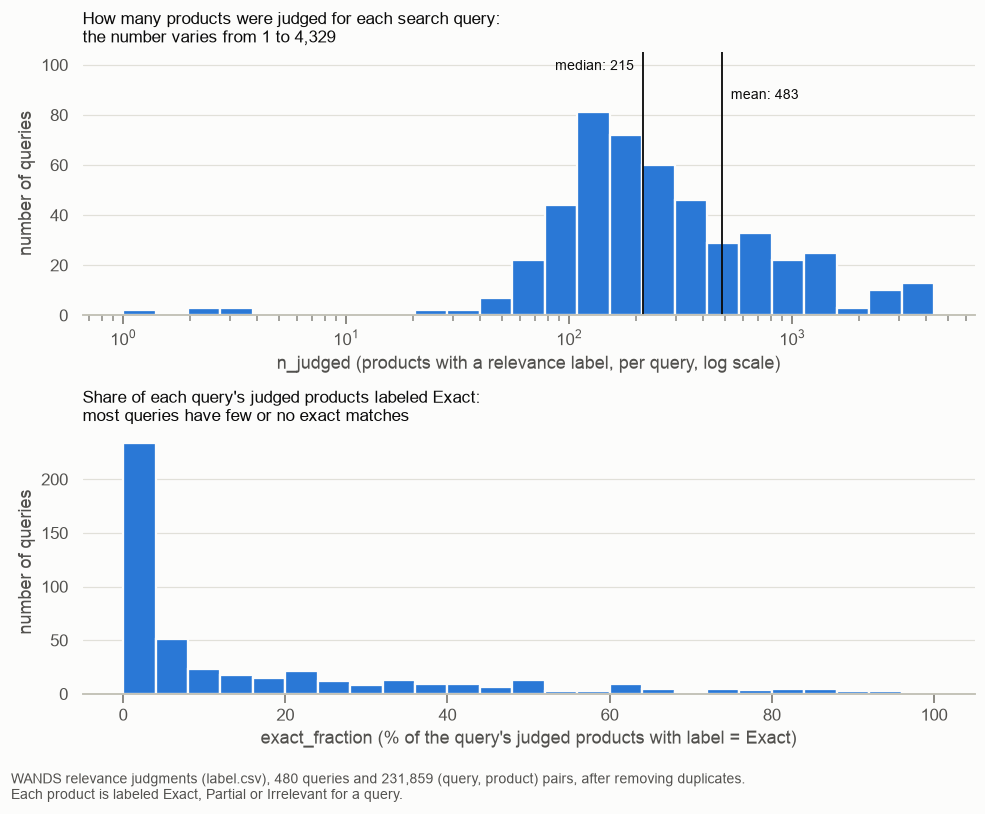

In [20]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 7))

sns.histplot(profile["n_judged"], log_scale=True, bins=25, color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=top)
top.grid(axis="x", visible=False)
top.margins(y=0.3)
top.set_title("How many products were judged for each search query:\nthe number varies from 1 to 4,329")
top.set_xlabel("n_judged (products with a relevance label, per query, log scale)")
top.set_ylabel("number of queries")
plots.reference_line(top, profile["n_judged"].median(), f"median: {profile['n_judged'].median():.0f}", ha="right")
plots.reference_line(top, profile["n_judged"].mean(), f"mean: {profile['n_judged'].mean():.0f}", y_fraction=0.82)

sns.histplot(profile["exact_fraction"] * 100, bins=range(0, 104, 4), color=plots.SERIES_1, alpha=1,
             edgecolor=plots.SURFACE, linewidth=1.5, ax=bottom)
bottom.grid(axis="x", visible=False)
bottom.set_title("Share of each query's judged products labeled Exact:\nmost queries have few or no exact matches")
bottom.set_xlabel("exact_fraction (% of the query's judged products with label = Exact)")
bottom.set_ylabel("number of queries")

fig.tight_layout()
plots.add_caption(fig, f"WANDS relevance judgments (label.csv), {len(profile)} queries and {len(unique_labels):,} "
                       "(query, product) pairs, after removing duplicates. Each product is labeled Exact, Partial or "
                       "Irrelevant for a query.", width=115)
plt.show()

**Conclusões**

- **O número de produtos julgados varia muito entre as queries:** de 1 a 4.329, com mediana de 215 e média de 483. A média esconde isso: 10% das queries concentram 47,1% dos pares.
- **A cobertura é menor do que a média sugere:** na mediana, cada query tem 0,50% do catálogo julgado (na média, 1,12%).
- **101 queries (21%) não têm nenhum Exact.** Se só Exact contasse como relevante, não daria para medir essas queries. Próxima etapa: considerar isso ao definir o que conta como relevante.
- **1 query não tem nenhum produto relevante:** "drudge report", com um único produto, Irrelevant. Proposta: ela fica na divisão, mas sai das métricas que exigem um produto relevante.
- **Há queries que não parecem buscas por produto:** "promo codes or discounts" e "drudge report", por exemplo. Próxima etapa: observar isso na análise de erros.

### 4.4 · Perfil de `label` por produto

Quantas vezes cada produto foi julgado? Se poucos produtos concentrarem os julgamentos, o modelo veria sempre os mesmos exemplos.

In [21]:
judgments_per_product = unique_labels.groupby("product_id").size()
display(judgments_per_product.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame("judgments").T)

product_labels = unique_labels.groupby(["product_id", "label"]).size().unstack(fill_value=0)
print(f"products with at least one Exact:   {(product_labels['Exact'] > 0).sum():>6,}")
print(f"products with no Exact:             {(product_labels['Exact'] == 0).sum():>6,}")
print(f"products that are only Irrelevant:  {((product_labels['Exact'] == 0) & (product_labels['Partial'] == 0)).sum():>6,}")
print(f"products both Exact and Irrelevant: {((product_labels['Exact'] > 0) & (product_labels['Irrelevant'] > 0)).sum():>6,}")

,count,mean,std,min,50%,90%,99%,max
judgments,42986.0,5.4,4.4,1.0,4.0,12.0,18.0,45.0


products with at least one Exact:   20,741
products with no Exact:             22,245
products that are only Irrelevant:     983
products both Exact and Irrelevant: 13,605


**Conclusões**

- Os julgamentos não se concentram em poucos produtos: a mediana é 4 por produto, e o máximo é 45.
- **A relevância depende da query, não só do produto:** 13.605 produtos são Exact para uma query e Irrelevant para outra. Isso reforça a decisão de não usar `product_id` como feature: o modelo precisa olhar a relação entre a query e o produto.
- Só 983 produtos são Irrelevant em todas as queries em que aparecem.

### 4.5 · `product_class` concorda com `query_class`?

Com que frequência o `product_class` de um produto contém a `query_class` da query, para cada `label`? Isso mostra o quanto a categoria ajuda a separar os rótulos e testa a decisão de não filtrar por categoria. É só uma análise: `query_class` não entra no sistema.

In [22]:
pairs = (
    unique_labels
    .merge(queries[["query_id", "query_class"]], on="query_id")
    .merge(products[["product_id", "product_class"]], on="product_id")
    .dropna(subset=["query_class", "product_class"])
)
pairs["class_match"] = [
    query_class in data.split_product_classes(product_class)
    for query_class, product_class in zip(pairs["query_class"], pairs["product_class"])
]
print(f"pairs with both values known: {len(pairs):,}")

match_by_label = pairs.groupby("label")["class_match"].agg(pairs="size", match_pct=lambda s: s.mean() * 100).round(1)
display(match_by_label)
exact_pairs = pairs[pairs["label"] == "Exact"]
print(f"Exact pairs whose product_class does not contain query_class: {(~exact_pairs['class_match']).sum():,}")

pairs with both values known: 213,745


,pairs,match_pct
label,,
Exact,23571,74.0
Irrelevant,56546,5.1
Partial,133628,54.4


Exact pairs whose product_class does not contain query_class: 6,138


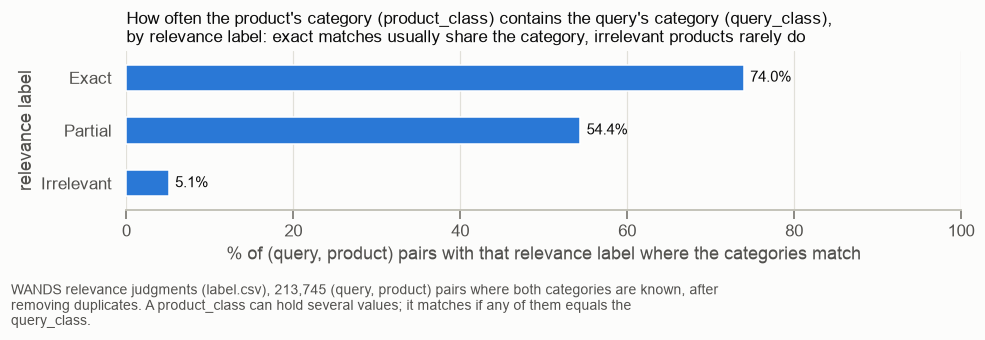

In [23]:
order = ["Exact", "Partial", "Irrelevant"]

fig, ax = plt.subplots(figsize=(9, 2.6))
sns.barplot(x=match_by_label.loc[order, "match_pct"], y=order, color=plots.SERIES_1, saturation=1, width=0.5, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4, color=plots.PRIMARY_INK)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_title("How often the product's category (product_class) contains the query's category (query_class),\n"
             "by relevance label: exact matches usually share the category, irrelevant products rarely do")
ax.set_xlabel("% of (query, product) pairs with that relevance label where the categories match")
ax.set_ylabel("relevance label")
fig.tight_layout()
plots.add_caption(fig, f"WANDS relevance judgments (label.csv), {len(pairs):,} (query, product) pairs where both "
                       "categories are known, after removing duplicates. A product_class can hold several values; "
                       "it matches if any of them equals the query_class.", width=110)
plt.show()

**Conclusões**

- **A categoria é um sinal forte:** o `product_class` contém a `query_class` em 74,0% dos pares Exact, em 54,4% dos Partial e em só 5,1% dos Irrelevant. Isso sustenta testar a semelhança entre a query e o `category_hierarchy` como feature do ranking.
- **Mas não serve como filtro:** 26% dos pares Exact (6.138) têm `product_class` sem a `query_class`. Um filtro por categoria esconderia esses produtos, mesmo com a categoria certa em mãos.
- Lembrando que `query_class` não entra no sistema; esta é só uma análise.

### 4.6 · Como dividir as queries

O dataset não tem divisão oficial, então definimos a nossa. Este é o raciocínio, que está formalizado em `docs/EVALUATION.md`.

**Cada query fica inteira em uma única parte**, qualquer que seja o número de produtos julgados. Assim, validação e teste simulam buscas que o sistema nunca viu. Se os produtos de uma query fossem separados, o modelo já teria visto essa busca no treino, e a nota sairia melhor do que na prática.

**Não dá para estratificar por `query_class`**, porque a maioria dos valores tem menos de 3 queries (Etapa 3). Estratificar é manter a mesma proporção de cada grupo em todas as partes.

**Estratificamos por duas informações**, porque as queries variam muito nas duas:
- `exact_fraction`: a porcentagem dos produtos julgados da query com `label` = Exact. Em uma query com muitos Exact, é mais fácil colocar um deles no topo. Um sorteio simples poderia deixar uma parte mais fácil que a outra.
- `n_judged`: o número de produtos julgados da query. Define quantos exemplos cada parte recebe.

Os rótulos só decidem em qual parte cada query fica; o modelo não recebe essa informação, então isso não é vazamento de dados.

A célula abaixo mostra os grupos e simula 200 sorteios, com a proporção **ilustrativa** de 70/15/15, medindo a fração dos pares (query, produto) que cai em cada parte. Com 15% das queries, o teste só teria 15% dos pares se as queries tivessem tamanhos parecidos.

In [24]:
groups = split.stratification_groups(profile)
group_table = groups.str.split("|", expand=True).set_axis(["exact_fraction_band", "n_judged_band"], axis=1)
display(pd.crosstab(group_table["exact_fraction_band"], group_table["n_judged_band"])
        .reindex(index=split.EXACT_FRACTION_NAMES, columns=split.N_JUDGED_NAMES))
print("n_judged range per band:")
display(profile.groupby(group_table["n_judged_band"])["n_judged"].agg(["min", "max", "count"]).reindex(split.N_JUDGED_NAMES))

ILLUSTRATIVE_FRACTIONS = {"train": 0.70, "validation": 0.15, "test": 0.15}
N_SIMULATIONS = 200


def simulate_pair_shares(strata: pd.Series) -> pd.DataFrame:
    """Share of pairs per part, in percent, for several random splits."""
    rows = []
    for seed in range(N_SIMULATIONS):
        assignment = split.stratified_split(strata, ILLUSTRATIVE_FRACTIONS, seed)
        rows.append(profile["n_judged"].groupby(assignment).sum() / profile["n_judged"].sum() * 100)
    return pd.DataFrame(rows)


quantiles = [0, 0.05, 0.5, 0.95, 1]
simulations = {
    "exact_fraction only": simulate_pair_shares(group_table["exact_fraction_band"]),
    "exact_fraction + n_judged": simulate_pair_shares(groups),
}
for name, shares in simulations.items():
    print(f"share of pairs per part, {name}:")
    display(shares[list(ILLUSTRATIVE_FRACTIONS)].quantile(quantiles).round(1))

n_judged_band,low,medium,high
exact_fraction_band,,,
none,50,26,25
up_to_2pct,18,36,52
2_to_10pct,30,21,37
over_10pct,65,74,46


n_judged range per band:


,min,max,count
n_judged_band,,,
low,1,149,163
medium,150,340,157
high,344,4329,160


share of pairs per part, exact_fraction only:


,train,validation,test
0.00,62.7,9.7,8.2
0.05,66.0,11.3,10.8
0.50,70.1,14.9,14.3
0.95,75.3,19.0,18.5
1.00,76.4,21.7,22.2


share of pairs per part, exact_fraction + n_judged:


,train,validation,test
0.00,63.6,11.5,10.8
0.05,66.3,12.8,11.8
0.50,69.9,15.4,14.4
0.95,73.3,18.7,17.1
1.00,77.2,20.6,19.1


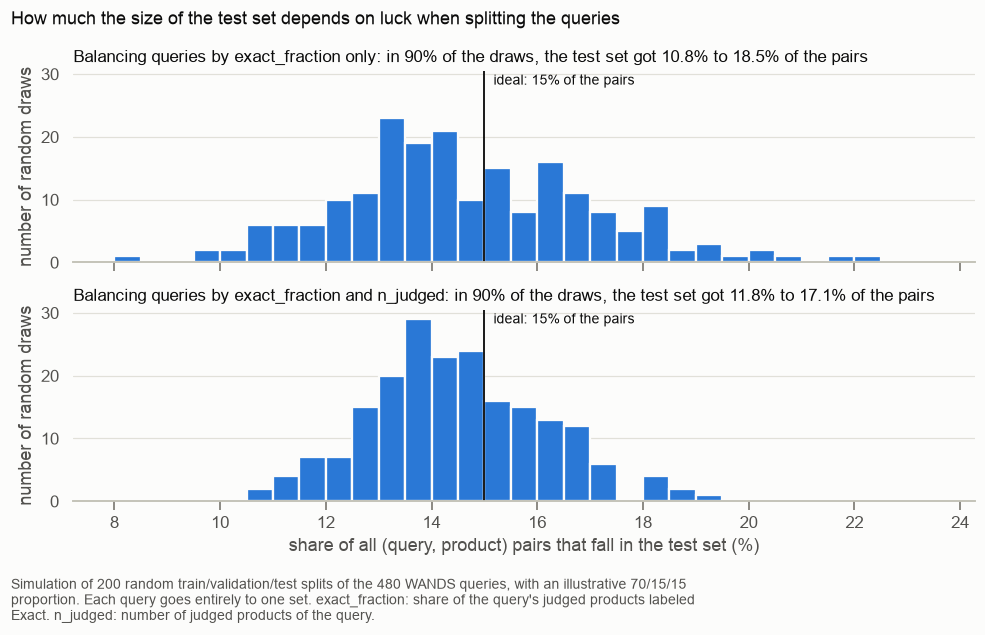

In [25]:
bins = np.arange(8, 24, 0.5)
fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, sharey=True)
panel_names = {
    "exact_fraction only": "Balancing queries by exact_fraction only",
    "exact_fraction + n_judged": "Balancing queries by exact_fraction and n_judged",
}

for ax, (name, shares) in zip(axes, simulations.items()):
    sns.histplot(shares["test"], bins=bins, color=plots.SERIES_1, alpha=1,
                 edgecolor=plots.SURFACE, linewidth=1.5, ax=ax)
    ax.grid(axis="x", visible=False)
    low, high = shares["test"].quantile([0.05, 0.95])
    ax.set_title(f"{panel_names[name]}: in 90% of the draws, the test set got {low:.1f}% to {high:.1f}% of the pairs")
    ax.set_ylabel("number of random draws")
    plots.reference_line(ax, 15, "ideal: 15% of the pairs")

axes[1].set_xlabel("share of all (query, product) pairs that fall in the test set (%)")
fig.suptitle("How much the size of the test set depends on luck when splitting the queries", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plots.add_caption(fig, f"Simulation of {N_SIMULATIONS} random train/validation/test splits of the {len(profile)} WANDS queries, with an "
                       "illustrative 70/15/15 proportion. Each query goes entirely to one set. exact_fraction: share of the "
                       "query's judged products labeled Exact. n_judged: number of judged products of the query.", width=115)
plt.show()

**Conclusões**

- Os 12 grupos são viáveis: o menor tem 18 queries.
- Com 15% das queries, a fração de pares no teste varia bastante de um sorteio para outro, porque as queries têm tamanhos muito diferentes.
- Usar as duas informações reduz essa variação: em 90% dos sorteios, o teste fica entre 11,8% e 17,1% dos pares, contra 10,8% e 18,5% usando só `exact_fraction`. O maior valor também cai, de 22,2% para 19,1%.
- O ganho é moderado, e o custo é quase zero. **Decisão: estratificar por `exact_fraction` e `n_judged`.**
- A proporção final e a seed ainda não foram definidas. A seed não pode ser escolhida olhando resultados de modelos.
- O número de palavras de `query` não entra na estratificação, para não criar grupos pequenos demais. Conferimos depois da divisão.
- Falta manter "leather chair" e "leather chairs" na mesma parte (Etapa 3): `stratified_split` ainda não faz isso.

## Etapa 5 · Pontos que afetam a avaliação

### 5.1 · Viés de pooling

**Pooling** é a forma comum de montar um gabarito de busca: como não dá para julgar 43 mil produtos para cada query, as pessoas julgam só os candidatos que algum buscador retornou. O efeito colateral é que produtos que aquele buscador não encontrou ficam sem rótulo.

Não sabemos como os candidatos foram escolhidos aqui, então olhamos dois sinais indiretos:
1. Os produtos julgados têm mais palavras em comum com a query do que produtos aleatórios?
2. Dos produtos que contêm todas as palavras da query, quantos foram julgados?

O texto do produto aqui é `product_name`, `product_class` e `category_hierarchy`.

In [26]:
catalog_text = (
    products["product_name"].fillna("") + " "
    + products["product_class"].fillna("") + " "
    + products["category_hierarchy"].fillna("")
)
tokens_by_product = dict(zip(products["product_id"], catalog_text.map(profiling.simple_tokens)))
tokens_by_query = dict(zip(queries["query_id"], queries["query"].map(profiling.simple_tokens)))

overlap_rows = unique_labels[["query_id", "product_id", "label"]].copy()
overlap_rows["overlap"] = [
    profiling.token_overlap(tokens_by_query[q], tokens_by_product[p])
    for q, p in zip(overlap_rows["query_id"], overlap_rows["product_id"])
]

N_RANDOM_PRODUCTS = 200
rng = np.random.default_rng(SAMPLE_SEED)
product_ids = products["product_id"].to_numpy()
random_overlap = pd.Series({
    query_id: np.mean([
        profiling.token_overlap(query_tokens, tokens_by_product[p])
        for p in rng.choice(product_ids, N_RANDOM_PRODUCTS, replace=False)
    ])
    for query_id, query_tokens in tokens_by_query.items()
})
judged_overlap = overlap_rows.groupby("query_id")["overlap"].mean()

print(f"mean overlap per query, median across queries, judged products: {judged_overlap.median():.3f}")
print(f"mean overlap per query, median across queries, random products: {random_overlap.median():.3f}")

by_label = overlap_rows.groupby("label")["overlap"].agg(
    pairs="size",
    mean_overlap="mean",
    zero_overlap_pct=lambda s: (s == 0).mean() * 100,
).round(3)
display(by_label.loc[["Exact", "Partial", "Irrelevant"]])

inverted_index = {}
for product_id, tokens in tokens_by_product.items():
    for token in tokens:
        inverted_index.setdefault(token, set()).add(product_id)

judged_by_query = unique_labels.groupby("query_id")["product_id"].agg(set)
coverage_rows = []
for query_id, query_tokens in tokens_by_query.items():
    postings = [inverted_index.get(token, set()) for token in query_tokens]
    matching = set.intersection(*postings) if postings else set()
    coverage_rows.append({
        "query_id": query_id,
        "all_tokens_match": len(matching),
        "matches_judged": len(matching & judged_by_query.get(query_id, set())),
    })
coverage = pd.DataFrame(coverage_rows).set_index("query_id")
with_matches = coverage[coverage["all_tokens_match"] > 0]
judged_share = with_matches["matches_judged"] / with_matches["all_tokens_match"] * 100

print(f"queries with at least one product matching all tokens: {len(with_matches)}")
print(f"products matching all tokens, summed over queries:     {with_matches['all_tokens_match'].sum():,}")
print(f"of those, judged for that query:                       {with_matches['matches_judged'].sum():,}")
print(f"share of matches judged per query, median:             {judged_share.median():.1f}%")
print(f"queries where every match was judged:                  {(judged_share == 100).sum()}")

mean overlap per query, median across queries, judged products: 0.485
mean overlap per query, median across queries, random products: 0.018


,pairs,mean_overlap,zero_overlap_pct
label,,,
Exact,25470,0.672,4.908
Partial,145670,0.491,2.732
Irrelevant,60719,0.424,11.545


queries with at least one product matching all tokens: 233
products matching all tokens, summed over queries:     12,756
of those, judged for that query:                       10,539
share of matches judged per query, median:             100.0%
queries where every match was judged:                  193


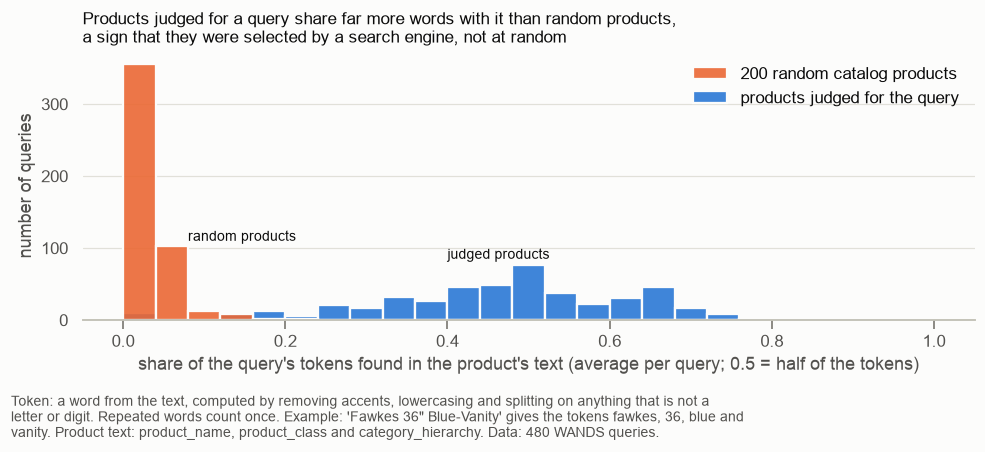

In [27]:
comparison = pd.concat([
    pd.DataFrame({"overlap": random_overlap, "products": f"{N_RANDOM_PRODUCTS} random catalog products"}),
    pd.DataFrame({"overlap": judged_overlap, "products": "products judged for the query"}),
])

fig, ax = plt.subplots(figsize=(9, 3.6))
sns.histplot(comparison, x="overlap", hue="products", bins=np.arange(0, 1.04, 0.04), multiple="layer", alpha=0.9,
             palette={f"{N_RANDOM_PRODUCTS} random catalog products": plots.SERIES_2, "products judged for the query": plots.SERIES_1},
             edgecolor=plots.SURFACE, linewidth=1.5, ax=ax)
ax.grid(axis="x", visible=False)
ax.set_title("Products judged for a query share far more words with it than random products,\n"
             "a sign that they were selected by a search engine, not at random")
ax.set_xlabel("share of the query's tokens found in the product's text (average per query; 0.5 = half of the tokens)")
ax.set_ylabel("number of queries")
ax.annotate("random products", xy=(0.08, 110), color=plots.PRIMARY_INK, fontsize=9)
ax.annotate("judged products", xy=(0.40, 85), color=plots.PRIMARY_INK, fontsize=9)
sns.move_legend(ax, "upper right", title=None)
fig.tight_layout()
plots.add_caption(fig, plots.TOKEN_DEFINITION + " Product text: product_name, product_class and category_hierarchy. "
                       f"Data: {len(queries)} WANDS queries.", width=115)
plt.show()

**Conclusões**

- **Os produtos julgados não são uma amostra aleatória:** em média, têm 48,5% das palavras da query, contra 1,8% de produtos aleatórios (medianas entre as queries). Isso é sinal de que os candidatos foram escolhidos por algo ligado às palavras, ou seja, há pooling.
- **O gabarito cobre bem os produtos que têm todas as palavras da query:** há 12.756 casos assim, e 10.539 (83%) foram julgados. Em 193 das 233 queries com algum caso, todos foram julgados. Um buscador por palavras deve encontrar poucos produtos sem rótulo.
- **Um sistema semântico pode ser prejudicado:** ele pode retornar produtos relevantes que não têm as palavras da query, e é mais provável que estes estejam sem rótulo. Por isso reportar a porcentagem de resultados com rótulo é essencial na comparação.
- **Mas o pooling não foi só por palavras:** 4,9% dos pares Exact, 2,7% dos Partial e 11,5% dos Irrelevant não têm nenhuma palavra em comum com a query. Esse texto do produto não inclui `product_description` nem `product_features`, então parte desses casos pode ter a palavra nessas colunas.
- **Só palavras em comum não bastam para ordenar:** a média é 0,672 em Exact, 0,491 em Partial e 0,424 em Irrelevant. Os Irrelevant também têm muitas palavras da query, e isso justifica um modelo de ranking com outros sinais.
- 247 das 480 queries não têm nenhum produto com todas as palavras nesse texto.

### 5.2 · Normalização de texto

O que já vem pronto e o que o processamento precisa tratar? Query e produto precisam passar pelo mesmo tratamento, senão palavras iguais não se encontram. Também vemos quais palavras das queries não existem no catálogo, porque um buscador por palavras não consegue encontrá-las.

In [28]:
text_columns = {"product_name": products["product_name"], "product_description": products["product_description"].dropna(), "query": queries["query"]}

rows = {}
for name, column in text_columns.items():
    rows[name] = {
        "rows": len(column),
        "has_uppercase": column.str.contains(r"[A-Z]").sum(),
        "spaced_comma": column.str.contains(" , ", regex=False).sum(),
        "two_apostrophes": column.str.contains("''", regex=False).sum(),
        "double_quote": column.str.contains('"', regex=False).sum(),
        "html_entity": column.str.contains(r"&[a-z]+;").sum(),
        "non_ascii": column.str.contains(r"[^\x00-\x7f]").sum(),
    }
display(pd.DataFrame(rows).T)

non_ascii_counts = Counter(
    char for text in pd.concat([products["product_name"], products["product_description"].dropna()])
    for char in text if ord(char) > 127
)
print("most common non-ASCII characters:", non_ascii_counts.most_common(10))

catalog_vocabulary = set(inverted_index)
for text in products["product_description"].dropna():
    catalog_vocabulary |= profiling.simple_tokens(text)
print(f"catalog vocabulary size: {len(catalog_vocabulary):,}")

missing_tokens = {q: tokens - catalog_vocabulary for q, tokens in tokens_by_query.items()}
queries_with_missing = {q: sorted(t) for q, t in missing_tokens.items() if t}
print(f"queries with a token missing from the catalog: {len(queries_with_missing)}")
display(pd.DataFrame({
    "query": queries.set_index("query_id").loc[list(queries_with_missing), "query"],
    "missing_tokens": pd.Series(queries_with_missing),
}))

,rows,has_uppercase,spaced_comma,two_apostrophes,double_quote,html_entity,non_ascii
product_name,42994,0,935,10291,0,0,918
product_description,36986,0,30929,3935,0,0,6882
query,480,0,1,0,3,0,0


most common non-ASCII characters: [('’', 5707), ('é', 2051), ('–', 1006), ('”', 999), ('®', 691), ('™', 487), ('°', 378), ('—', 364), ('“', 301), ('â', 190)]


catalog vocabulary size: 46,762
queries with a token missing from the catalog: 36


,query,missing_tokens
20,foutains with brick look,[foutains]
23,stoneford end tables white and wood,[stoneford]
62,7qt slow cooker,[7qt]
77,sancroft armchair,[sancroft]
78,dorel vanity,[dorel]
87,vlad modular sectional,[vlad]
90,filaret outdoor sofa,[filaret]
98,gracie oaks 62 oller 14 ceiling fan,[oller]
179,promo codes or discounts,"[discounts, promo]"
190,benjiamino faux leather power lift chair,[benjiamino]


**Conclusões**

- **Já vem pronto:** o texto está em minúsculas e sem entidades HTML.
- **Acentos precisam de tratamento:** as queries não têm caracteres não ASCII, mas 918 valores de `product_name` e 6.882 de `product_description` têm, como `é` (2.051 vezes). Sem tratamento, "decor" não encontra "décor". Proposta: remover acentos de query e produto. `profiling.simple_tokens` já faz isso, e a correção mudou pouco os números desta etapa.
- **Polegadas se resolvem com o mesmo tratamento:** `36"` na query e `18 ''` em `product_name` (10.291 valores têm `''`) viram só o número quando a pontuação é descartada. Isso responde à pergunta da Etapa 3, mas perde a informação de que o número é uma medida.
- **Proposta:** query e produto passam pelo mesmo processamento, sempre.
- **36 queries (7,5%) têm palavras que não existem no catálogo**, considerando `product_name`, `product_class`, `category_hierarchy` e `product_description`, mas não `product_features`. Lendo a lista, vemos erros de digitação ("foutains", "biycicle", "ligth"), nomes próprios ("stoneford", "filaret"), palavras grudadas ("roomtables", "7qt") e outras lojas ("lowes", "urban outfitters"). Essa classificação é nossa leitura.
- **Um buscador só por palavras não encontra essas palavras.** É um argumento para comparar com uma abordagem semântica ou híbrida, como o desafio pede.